# ⚽ El Ojo del Árbitro Digital

**Visión Computacional – Trabajo Práctico**

Sistema de visión artificial que interpreta un partido de fútbol: procesa un video, toma **un fotograma al azar** y, sobre esa imagen, resalta los elementos clave del juego con el siguiente código de colores:

| Elemento | Color |
|---|---|
| Jugadores | 🔵 **Azul** (contorno) |
| Pelota | 🔴 **Rojo** (contorno) |
| Líneas de la cancha | 🟢 **Verde** |

> Si en el fotograma elegido no aparece alguno de los elementos (por ejemplo, una toma de la tribuna), **no se marca nada** para ese elemento.

El cuaderno presenta **dos versiones** del sistema, que comparten la segmentación de la cancha:

| | **Parte A – Versión clásica** | **Parte B – Versión con YOLO** |
|---|---|---|
| Jugadores | Segmentación por color (no‑pasto) + morfología + filtros de forma | Detector YOLO (cajas) + segmentación por color dentro de cada caja |
| Pelota | Color + **circularidad** + anillo de pasto alrededor | Detector YOLO; si falla, el método clásico |
| Líneas | Color HSV + top‑hat + **Canny** + **Hough** | Ídem (con la máscara de jugadores de YOLO) |
| Requiere | Solo OpenCV y NumPy | Además `ultralytics` (PyTorch) |

### Flujo general

```
video ──► fotograma aleatorio ──► máscara de pasto (HSV) ──► región de la cancha
                                         │
             ┌───────────────────────────┼───────────────────────────┐
             ▼                           ▼                           ▼
        JUGADORES                     PELOTA                      LÍNEAS
   A: blobs no-verdes           A: blobs blancos circulares   blanco HSV + top-hat
   B: YOLO + ROI no-verde       B: YOLO (o A como respaldo)     → Canny → Hough
             │                           │                           │
             └──────────────► imagen anotada (azul / rojo / verde) ◄─┘
```

## 1. Importación de librerías

- `opencv-python` (**cv2**): todo el procesamiento de imágenes (espacios de color, umbralización, morfología, bordes, contornos, Hough).
- `numpy`: las imágenes son matrices; lo usamos para operar con ellas.
- `matplotlib`: para mostrar resultados dentro del cuaderno.

La Parte A usa **solo** estas librerías. El detector YOLO (Parte B) se instala e importa más adelante, en su propia sección.

In [140]:
import os
import random

import cv2  # OpenCV: procesamiento de imágenes
import matplotlib.pyplot as plt  # visualización
import numpy as np  # operaciones con matrices

print("OpenCV", cv2.__version__)

OpenCV 5.0.0


## 2. Parámetros del sistema

Agrupamos todos los parámetros ajustables en una sola celda (formularios de Colab `@param`) para poder calibrarlos según el video.

**Espacio de color HSV.** En lugar de BGR trabajamos en HSV (*Hue, Saturation, Value*), porque separa el **tono** del color de su **brillo**: el pasto es "verde" tanto al sol como a la sombra, lo que en BGR sería muy difícil de expresar con un único rango. En OpenCV:
- **H** (tono) va de 0 a 179 → el verde está aproximadamente entre 30 y 90.
- **S** (saturación) y **V** (brillo) van de 0 a 255.
- El **blanco** de las líneas tiene **saturación baja** y **brillo alto**.

**Umbrales relativos al pasto (calibración automática).** El color exacto del pasto, de las líneas y de la pelota cambia mucho de un video a otro (iluminación, compresión, ajustes de contraste y saturación del video). Por eso los umbrales de saturación y brillo **no son números fijos**: en cada fotograma medimos la saturación y el brillo *típicos* (mediana) del pasto y los umbrales se expresan **en relación con ellos**. Por ejemplo, "blanco" = *menos del 60 % de la saturación del pasto*. Así el mismo código funciona con videos de distinto contraste sin recalibrar.

Los umbrales de tamaño (áreas, grosor de línea) están pensados para un video de **1280 px de ancho**; el código los reescala automáticamente según la resolución real.

In [141]:
# --- Video ---------------------------------------------------------------
VIDEO_PATH = "VideoHolandaJapon_Contraste.mp4"  # @param {type:"string"}
SEMILLA = -1                # @param {type:"integer"}  (-1 = azar real; otro valor = reproducible)

# --- Pasto (verde) en HSV -----------------------------------------------
H_VERDE_MIN = 30   # @param {type:"slider", min:0, max:179, step:1}
H_VERDE_MAX = 90   # @param {type:"slider", min:0, max:179, step:1}
S_VERDE_MIN = 40   # @param {type:"slider", min:0, max:255, step:1}  (primera pasada, umbral amplio)
V_VERDE_MIN = 40   # @param {type:"slider", min:0, max:255, step:1}
FACTOR_S_PASTO = 0.6   # @param {type:"number"}  pasto = saturación ≥ 60 % de la saturación típica del pasto
AREA_MIN_CANCHA = 0.10  # @param {type:"number"}  fracción mínima de la imagen que debe ser cancha

# --- Jugadores (versión clásica) -----------------------------------------
GROSOR_LINEA = 10      # @param {type:"integer"}  (px, para 1280 de ancho) lo que sea más fino se considera línea
AREA_JUG_MIN = 150     # @param {type:"integer"}  (px², para 1280 de ancho)
AREA_JUG_MAX = 6000    # @param {type:"integer"}  (px², para 1280 de ancho)
ALTO_JUG_MIN = 20      # @param {type:"integer"}  (px, para 1280 de ancho) más bajo que esto no es un jugador (p. ej. la pelota)
ANCHO_JUG_MAX = 0.12   # @param {type:"number"}   ancho máximo como fracción del ancho de la imagen
SOLIDEZ_MIN = 0.40     # @param {type:"number"}   área / área de la envolvente convexa

# --- Líneas (blanco) -----------------------------------------------------
FACTOR_S_BLANCO = 0.75 # @param {type:"number"}  blanco = saturación < 75 % de la saturación típica del pasto
TOPHAT_UMBRAL = 25     # @param {type:"slider", min:0, max:255, step:1}
TOPHAT_KERNEL = 25     # @param {type:"integer"}  (px, para 1280 de ancho) debe ser más ancho que la línea más gruesa
CANNY_BAJO = 50        # @param {type:"integer"}
CANNY_ALTO = 150       # @param {type:"integer"}
HOUGH_UMBRAL = 40      # @param {type:"integer"}
HOUGH_LONG_MIN = 40    # @param {type:"integer"}
HOUGH_GAP_MAX = 10     # @param {type:"integer"}

# --- Pelota (método clásico) -----------------------------------------------
DELTA_V_PELOTA = 50          # @param {type:"integer"}  la pelota es al menos 50 niveles más brillante que el pasto
AREA_PELOTA_MIN = 15         # @param {type:"integer"}  (px², para 1280 de ancho)
AREA_PELOTA_MAX = 400        # @param {type:"integer"}  (px², para 1280 de ancho)
CIRCULARIDAD_MIN = 0.70      # @param {type:"number"}
ANILLO_PASTO_MIN = 0.85      # @param {type:"number"}  fracción de pasto alrededor de la pelota
ANILLO_OSCURO_MAX = 0.03     # @param {type:"number"}  fracción de píxeles oscuros alrededor (piernas)

# --- Detector YOLO (Parte B) ---------------------------------------------
MODELO_YOLO = "yolov8s.pt"  # @param ["yolov8n.pt", "yolov8s.pt", "yolov8m.pt"]
CONF_JUGADOR = 0.30         # @param {type:"slider", min:0.05, max:0.95, step:0.05}
CONF_PELOTA = 0.15          # @param {type:"slider", min:0.05, max:0.95, step:0.05}
IMGSZ_YOLO = 1280           # @param [640, 960, 1280]
USAR_RESPALDO_PELOTA = True  # @param {type:"boolean"}  si YOLO no ve la pelota, probar el método clásico

# Colores de dibujo. ATENCIÓN: OpenCV usa el orden BGR, no RGB.
AZUL = (255, 0, 0)
ROJO = (0, 0, 255)
VERDE = (0, 255, 0)

# Elementos estructurantes reutilizados en las operaciones morfológicas
KERNEL_3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
KERNEL_5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

## 3. Carga del video

Si el video indicado en `VIDEO_PATH` no existe y estamos en Colab, se abre un diálogo para subirlo desde la computadora. (También se puede montar Google Drive y poner en `VIDEO_PATH` la ruta dentro de `/content/drive/...`).

Luego abrimos el video con `cv2.VideoCapture` y leemos sus propiedades: cantidad de fotogramas, FPS y resolución.

In [142]:
try:
    from google.colab import files  # solo existe dentro de Google Colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

# Si el archivo no está, lo pedimos al usuario (solo en Colab)
if EN_COLAB and not os.path.exists(VIDEO_PATH):
    print(f"No se encontró '{VIDEO_PATH}'. Subí el video del partido:")
    subidos = files.upload()
    VIDEO_PATH = next(iter(subidos))

assert os.path.exists(VIDEO_PATH), f"No existe el video: {VIDEO_PATH}"

# Abrimos el video y consultamos sus propiedades
cap = cv2.VideoCapture(VIDEO_PATH)
TOTAL_FRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
FPS = cap.get(cv2.CAP_PROP_FPS)
ANCHO = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
ALTO = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()

print(f"Video: {VIDEO_PATH}")
print(f"Fotogramas: {TOTAL_FRAMES} | FPS: {FPS:.1f} | Duración: {TOTAL_FRAMES / max(FPS, 1):.1f} s")
print(f"Resolución: {ANCHO} x {ALTO}")

Video: VideoHolandaJapon_Contraste.mp4
Fotogramas: 230 | FPS: 25.0 | Duración: 9.2 s
Resolución: 1920 x 1080


## 4. Selección de un fotograma al azar

1. Generamos un número entero aleatorio entre `0` y `TOTAL_FRAMES - 1` con `random`.
2. Con `cap.set(cv2.CAP_PROP_POS_FRAMES, indice)` posicionamos el video en ese fotograma.
3. `cap.read()` devuelve la imagen como una matriz NumPy de forma `(alto, ancho, 3)` en orden **BGR**.

Para mostrarla con `matplotlib` hay que convertirla a RGB con `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)`; si no, el rojo y el azul aparecen intercambiados.

**Este mismo fotograma se analiza con las dos versiones (A y B)**, para poder compararlas.

Fotograma elegido: 182 (t = 7.28 s)


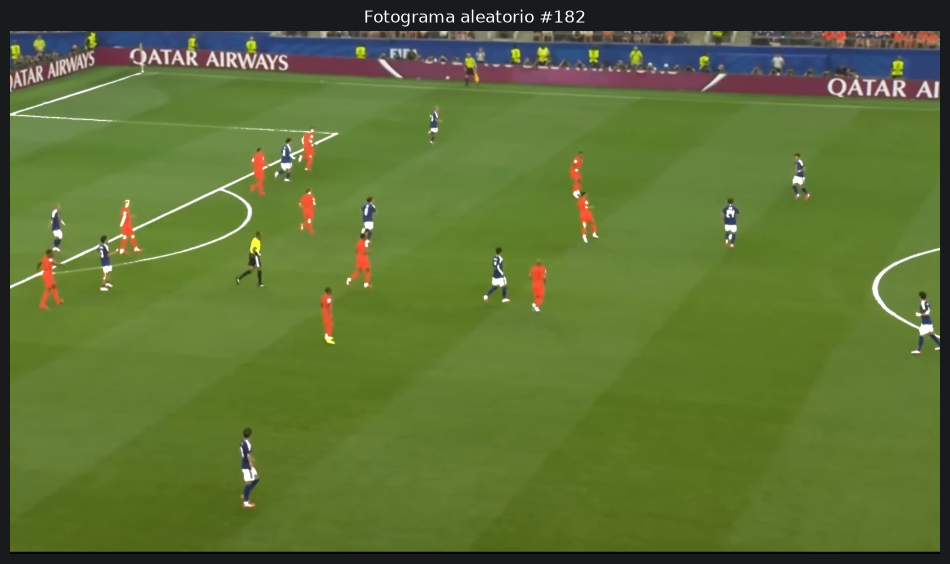

In [143]:
# Generador aleatorio: con SEMILLA >= 0 los resultados son reproducibles
rng = random.Random(None if SEMILLA < 0 else SEMILLA)


def tomar_frame_aleatorio(ruta, generador):
    # Abre el video, salta a un fotograma al azar y lo devuelve junto a su índice
    cap = cv2.VideoCapture(ruta)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    for _ in range(5):  # algunos códecs fallan al saltar a ciertos frames: reintentamos
        indice = generador.randint(0, total - 1)
        cap.set(cv2.CAP_PROP_POS_FRAMES, indice)
        ok, frame = cap.read()
        if ok:
            cap.release()
            return frame, indice
    cap.release()
    raise RuntimeError("No se pudo leer un fotograma del video")


def bgr2rgb(img):
    # Convierte de BGR (OpenCV) a RGB (matplotlib)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


frame, indice = tomar_frame_aleatorio(VIDEO_PATH, rng)
print(f"Fotograma elegido: {indice} (t = {indice / max(FPS, 1):.2f} s)")

plt.figure(figsize=(12, 7))
plt.imshow(bgr2rgb(frame))
plt.title(f"Fotograma aleatorio #{indice}")
plt.axis("off")
plt.show()

## 5. Segmentación de la cancha por color (filtrado HSV + morfología)

Toda la detección se apoya en saber **dónde está el campo de juego**. Así evitamos marcar personas de la tribuna o carteles publicitarios.

1. **Conversión a HSV** con `cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)`.
2. **Umbralización por rango en dos pasadas** con `cv2.inRange` (los píxeles dentro del rango valen 255 y el resto 0):
   - *Primera pasada*, con un rango amplio de verde, solo para **medir** la saturación y el brillo típicos del pasto (la **mediana**, que no se ve afectada por los pocos píxeles de jugadores o líneas). Esa medida (`ref`) la usan después todas las etapas para fijar sus umbrales.
   - *Segunda pasada*, exigiendo una saturación de al menos `FACTOR_S_PASTO` × la del pasto → *máscara de pasto*. Esto es importante: con un video de contraste suave, los bordes difusos de los jugadores y las camisetas blancas toman un tinte verdoso, y con un umbral fijo bajo quedarían clasificados como pasto (los contornos de los jugadores "se encogen").
3. **Apertura morfológica** (`MORPH_OPEN` = erosión + dilatación): elimina puntitos verdes aislados (ruido) fuera de la cancha.
4. **Contornos** (`cv2.findContours`): nos quedamos con **todas las regiones verdes grandes** (más del 1 % de la imagen). Tomar solo la mayor sería un error: la línea de mitad de cancha o una línea del área parten el pasto en varios pedazos, y perderíamos media cancha.
5. **Envolvente convexa** (`cv2.convexHull`) de todas esas regiones, rellena: así la región de la cancha incluye también lo que está *sobre* el pasto (jugadores, líneas, pelota), que no es verde.
6. Si la cancha ocupa menos de `AREA_MIN_CANCHA` de la imagen, consideramos que **no hay cancha visible** (tribuna, primer plano, repetición) y no se marca nada.

Cancha visible: True (89% de la imagen)
Pasto típico: saturación 158, brillo 126


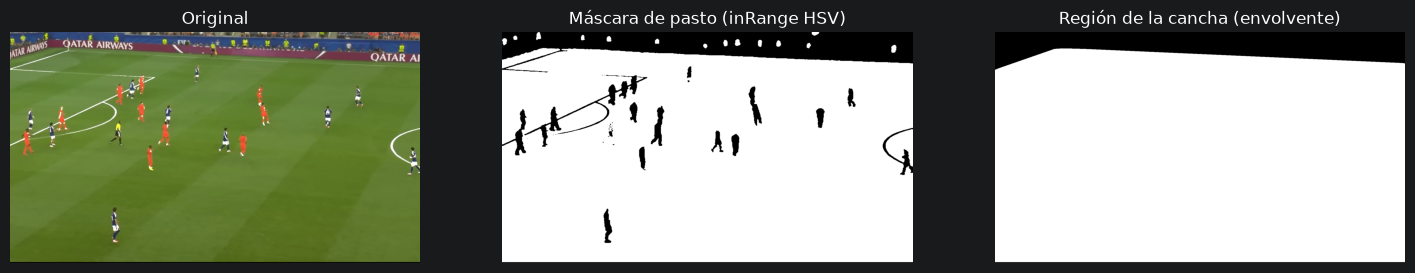

In [144]:
def segmentar_cancha(frame):
    alto, ancho = frame.shape[:2]
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

    # 1a) Primera pasada (rango amplio): medimos saturación y brillo típicos del pasto
    alto_hsv = np.array([H_VERDE_MAX, 255, 255])
    verde_amplio = cv2.inRange(hsv, np.array([H_VERDE_MIN, S_VERDE_MIN, V_VERDE_MIN]), alto_hsv)
    if cv2.countNonZero(verde_amplio) > 0:
        ref = {"s": float(np.median(hsv[:, :, 1][verde_amplio > 0])),
               "v": float(np.median(hsv[:, :, 2][verde_amplio > 0]))}
    else:
        ref = {"s": 128.0, "v": 128.0}  # sin verde: valores neutros (igual no habrá cancha)

    # 1b) Segunda pasada: pasto = verde con saturación cercana a la típica
    s_min = max(S_VERDE_MIN, int(FACTOR_S_PASTO * ref["s"]))
    pasto = cv2.inRange(hsv, np.array([H_VERDE_MIN, s_min, V_VERDE_MIN]), alto_hsv)

    # 2) Apertura morfológica: quita ruido pequeño
    pasto = cv2.morphologyEx(pasto, cv2.MORPH_OPEN, KERNEL_5)

    # 3) Regiones verdes grandes (las líneas parten el pasto en varios pedazos)
    cancha = np.zeros((alto, ancho), dtype=np.uint8)
    contornos, _ = cv2.findContours(pasto, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    grandes = [c for c in contornos if cv2.contourArea(c) > 0.01 * alto * ancho]
    if grandes:
        # 4) Envolvente convexa rellena de todas ellas: incluye jugadores y líneas
        envolvente = cv2.convexHull(np.vstack(grandes))
        cv2.drawContours(cancha, [envolvente], -1, 255, thickness=cv2.FILLED)

    # 5) ¿Hay suficiente cancha visible como para analizar la imagen?
    fraccion = cv2.countNonZero(cancha) / (alto * ancho)
    hay_cancha = fraccion >= AREA_MIN_CANCHA
    return pasto, cancha, hay_cancha, fraccion, ref


def mascara_blanca(hsv, ref, delta_v=None):
    # Píxeles "blancos": bastante menos saturados que el pasto y, si se pide, más brillantes
    s_max = int(FACTOR_S_BLANCO * ref["s"])
    v_min = 0 if delta_v is None else min(255, int(ref["v"] + delta_v))
    return cv2.inRange(hsv, np.array([0, 0, v_min]), np.array([179, s_max, 255]))


pasto, cancha, hay_cancha, fraccion, ref = segmentar_cancha(frame)
print(f"Cancha visible: {hay_cancha} ({fraccion:.0%} de la imagen)")
print(f"Pasto típico: saturación {ref['s']:.0f}, brillo {ref['v']:.0f}")

fig, ejes = plt.subplots(1, 3, figsize=(18, 5))
ejes[0].imshow(bgr2rgb(frame)); ejes[0].set_title("Original")
ejes[1].imshow(pasto, cmap="gray"); ejes[1].set_title("Máscara de pasto (inRange HSV)")
ejes[2].imshow(cancha, cmap="gray"); ejes[2].set_title("Región de la cancha (envolvente)")
for eje in ejes:
    eje.axis("off")
plt.show()

---
# PARTE A – Versión clásica (sin YOLO)

En esta versión **todo** se resuelve con técnicas vistas en clase: filtrado por color, morfología matemática, análisis de contornos y descriptores de forma, detección de bordes y transformada de Hough.

## A1. Jugadores: segmentación por color + morfología + filtros de forma → contorno azul

Idea: dentro de la cancha, **todo lo que no es pasto** es un jugador, el árbitro, una línea o la pelota. Separamos a los jugadores del resto por su **tamaño y forma**.

1. **Candidatos**: `NOT pasto AND cancha` (con la cancha erosionada un poco para no tomar el borde con los carteles).
2. **Apertura con un elemento estructurante del grosor de una línea** (`GROSOR_LINEA`): la erosión hace desaparecer todo lo que sea más fino que el elemento (las líneas de cal y la pelota) y la dilatación posterior devuelve su tamaño a lo que sobrevivió (los cuerpos).
3. **Cierre con un elemento vertical** (rectángulo alto y angosto): une cabeza, torso y piernas de un mismo jugador en una sola mancha.
4. **Reconstrucción de la silueta**: la apertura también "come" brazos y piernas finos; para recuperarlos dilatamos las manchas y hacemos un AND con los candidatos originales. Así obtenemos la silueta completa, pero solo alrededor de los cuerpos detectados.
5. **Contornos** con `cv2.findContours` y **filtros de forma** sobre cada uno:
   - **Área** entre `AREA_JUG_MIN` y `AREA_JUG_MAX` → descarta restos de líneas y manchas grandes.
   - **Altura** mínima `ALTO_JUG_MIN` → descarta la pelota, que en una toma cercana puede tener tanta área como un jugador lejano, pero es mucho más baja.
   - **Relación de aspecto** alto/ancho entre 0.4 y 5 → una persona es más alta que ancha (con margen para jugadores tirándose al piso).
   - **Ancho máximo** → descarta estructuras anchas como el arco y su red.
   - **Solidez** = área / área de la envolvente convexa ≥ `SOLIDEZ_MIN` → descarta formas muy irregulares o huecas (la red del arco, uniones de líneas).

Además devolvemos la **máscara de jugadores** (para que las camisetas blancas no se confundan con líneas o con la pelota) y sus **cajas** (`boundingRect`).

Jugadores detectados (clásico): 17


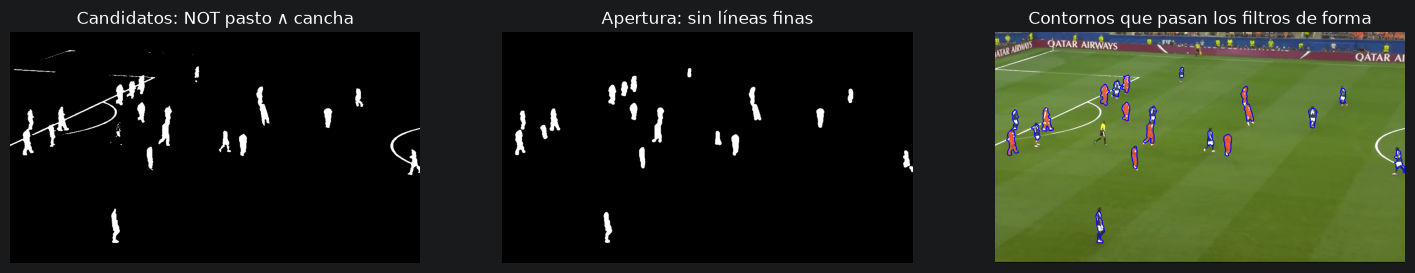

In [145]:
def jugadores_clasico(frame, pasto, cancha):
    alto, ancho = frame.shape[:2]
    escala = ancho / 1280  # los parámetros de tamaño están pensados para 1280 px de ancho

    # 1) Candidatos: lo que no es pasto, dentro de la cancha (sin su borde)
    interior = cv2.erode(cancha, KERNEL_5, iterations=3)
    no_pasto = cv2.bitwise_and(cv2.bitwise_not(pasto), interior)

    # 2) Apertura del grosor de una línea: borra líneas de cal y pelota, conserva cuerpos
    k = max(3, round(GROSOR_LINEA * escala) | 1)  # tamaño impar
    kernel_linea = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    sin_lineas = cv2.morphologyEx(no_pasto, cv2.MORPH_OPEN, kernel_linea)

    # 3) Cierre vertical: une cabeza, torso y piernas
    kernel_cuerpo = cv2.getStructuringElement(cv2.MORPH_RECT, (max(3, int(5 * escala)), max(5, int(21 * escala))))
    cuerpos = cv2.morphologyEx(sin_lineas, cv2.MORPH_CLOSE, kernel_cuerpo)

    # 4) Reconstrucción: recuperamos brazos y piernas alrededor de cada cuerpo
    siluetas = cv2.bitwise_and(no_pasto, cv2.dilate(cuerpos, KERNEL_5, iterations=2))
    siluetas = cv2.morphologyEx(siluetas, cv2.MORPH_CLOSE, KERNEL_3, iterations=2)

    # 5) Contornos + filtros de forma
    contornos = []
    cs, _ = cv2.findContours(siluetas, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    for c in cs:
        area = cv2.contourArea(c)
        _, _, w, h = cv2.boundingRect(c)
        if not (AREA_JUG_MIN * escala**2 <= area <= AREA_JUG_MAX * escala**2):
            continue                                   # muy chico o muy grande
        if h < ALTO_JUG_MIN * escala:
            continue                                   # muy bajo: pelota, restos de línea
        if not (0.4 <= h / w <= 5):
            continue                                   # no tiene proporciones de persona
        if w > ANCHO_JUG_MAX * ancho:
            continue                                   # demasiado ancho (arco, red)
        solidez = area / max(cv2.contourArea(cv2.convexHull(c)), 1)
        if solidez < SOLIDEZ_MIN:
            continue                                   # forma muy irregular
        contornos.append(c)

    mascara_jugadores = np.zeros((alto, ancho), dtype=np.uint8)
    cv2.drawContours(mascara_jugadores, contornos, -1, 255, thickness=cv2.FILLED)
    cajas = [cv2.boundingRect(c) for c in contornos]  # (x, y, w, h) de cada jugador
    return contornos, mascara_jugadores, cajas, no_pasto, sin_lineas


if hay_cancha:
    jugadores_a, mascara_jug_a, cajas_a, no_pasto, sin_lineas = jugadores_clasico(frame, pasto, cancha)
else:
    jugadores_a, mascara_jug_a, cajas_a = [], None, []
    no_pasto = sin_lineas = np.zeros(frame.shape[:2], np.uint8)
print(f"Jugadores detectados (clásico): {len(jugadores_a)}")

fig, ejes = plt.subplots(1, 3, figsize=(18, 5))
ejes[0].imshow(no_pasto, cmap="gray"); ejes[0].set_title("Candidatos: NOT pasto ∧ cancha")
ejes[1].imshow(sin_lineas, cmap="gray"); ejes[1].set_title("Apertura: sin líneas finas")
vista = frame.copy()
cv2.drawContours(vista, jugadores_a, -1, AZUL, 3)
ejes[2].imshow(bgr2rgb(vista)); ejes[2].set_title("Contornos que pasan los filtros de forma")
for eje in ejes:
    eje.axis("off")
plt.show()

## A2. Líneas de la cancha: color + top‑hat + Canny + Hough → verde

Las líneas de cal son **delgadas, claras y poco saturadas** sobre un fondo verde. Las aislamos así:

1. **Filtro de saturación (HSV)**: el blanco tiene saturación baja (`S < FACTOR_S_BLANCO` × saturación del pasto).
2. **Top‑hat morfológico** sobre la imagen en grises: `tophat = imagen − apertura(imagen)`. La apertura con un elemento estructurante grande (`TOPHAT_KERNEL`, más ancho que las líneas) "borra" las estructuras finas y claras, así que la resta deja **solo** esas estructuras (las líneas), aunque estén en una zona de sombra. Luego umbralizamos con `cv2.threshold`.
3. Combinamos ambas condiciones (AND) y nos quedamos solo con lo que está **dentro de la cancha** y **fuera de los jugadores** (las camisetas blancas no son líneas).
4. **Detector de bordes de Canny** sobre la **máscara de líneas** suavizada (filtro Gaussiano): obtiene los dos bordes de cada línea. Aplicarlo sobre la máscara (y no sobre la imagen original) lo hace independiente del contraste del video: en un video suave o desenfocado, el borde de una línea tenue tiene un gradiente muy bajo y Canny sobre la imagen lo pierde, mientras que en la máscara binaria el salto es siempre de 0 a 255.
5. **Transformada de Hough probabilística** (`cv2.HoughLinesP`): cada píxel de borde "vota" por todas las rectas que pasan por él en el espacio (ρ, θ); las rectas con suficientes votos (`HOUGH_UMBRAL`), una longitud mínima (`HOUGH_LONG_MIN`) y huecos tolerables (`HOUGH_GAP_MAX`) se devuelven como segmentos. Esto descarta ruido y reconstruye líneas interrumpidas por jugadores.

Los segmentos obtenidos (laterales, líneas de fondo, áreas, mitad de cancha) se dibujan en **verde**. Esta función la reutiliza también la Parte B.

Segmentos de línea detectados: 35


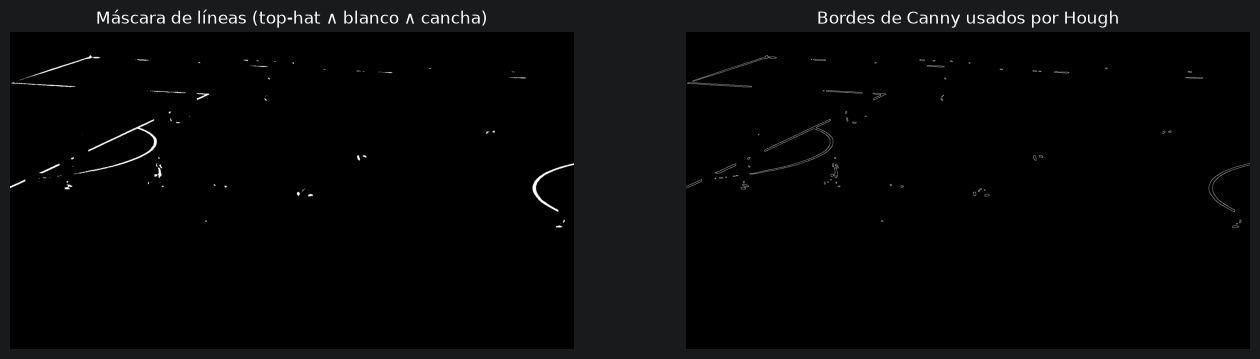

In [146]:
def detectar_lineas(frame, cancha, mascara_jugadores, ref):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # 1) Poco saturado (blanco/gris claro), relativo a la saturación del pasto
    poco_saturado = mascara_blanca(hsv, ref)

    # 2) Top-hat: resalta estructuras finas y más claras que su entorno.
    #    El elemento estructurante debe ser más ancho que las líneas (se reescala con la resolución)
    k = max(3, round(TOPHAT_KERNEL * frame.shape[1] / 1280) | 1)
    kernel_grande = cv2.getStructuringElement(cv2.MORPH_RECT, (k, k))
    tophat = cv2.morphologyEx(gris, cv2.MORPH_TOPHAT, kernel_grande)
    _, claro = cv2.threshold(tophat, TOPHAT_UMBRAL, 255, cv2.THRESH_BINARY)

    # 3) Combinación: claro AND poco saturado AND dentro de la cancha AND fuera de jugadores
    lineas = cv2.bitwise_and(claro, poco_saturado)
    lineas = cv2.bitwise_and(lineas, cancha)
    if mascara_jugadores is not None:
        jugadores_dilatados = cv2.dilate(mascara_jugadores, KERNEL_5, iterations=2)
        lineas = cv2.bitwise_and(lineas, cv2.bitwise_not(jugadores_dilatados))
    # (no aplicamos una apertura: borraría las líneas lejanas, de 2-3 px de ancho;
    #  los puntos sueltos los descarta Hough por no formar segmentos largos)

    # 4) Canny sobre la máscara de líneas suavizada: como la máscara es binaria, sus bordes
    #    son nítidos aunque en el video las líneas sean tenues o estén desenfocadas
    suavizada = cv2.GaussianBlur(lineas, (5, 5), 0)
    bordes = cv2.Canny(suavizada, CANNY_BAJO, CANNY_ALTO)

    # 5) Hough probabilístico: segmentos rectos
    segmentos = cv2.HoughLinesP(
        bordes, rho=1, theta=np.pi / 180, threshold=HOUGH_UMBRAL,
        minLineLength=HOUGH_LONG_MIN, maxLineGap=HOUGH_GAP_MAX,
    )
    # Cada segmento es (x1, y1, x2, y2); reshape unifica el formato entre versiones de OpenCV
    segmentos = [] if segmentos is None else list(segmentos.reshape(-1, 4))
    return segmentos, lineas, bordes


if hay_cancha:
    segmentos_a, mascara_lineas, bordes = detectar_lineas(frame, cancha, mascara_jug_a, ref)
else:
    segmentos_a, mascara_lineas, bordes = [], np.zeros(frame.shape[:2], np.uint8), np.zeros(frame.shape[:2], np.uint8)
print(f"Segmentos de línea detectados: {len(segmentos_a)}")

fig, ejes = plt.subplots(1, 2, figsize=(16, 5))
ejes[0].imshow(mascara_lineas, cmap="gray"); ejes[0].set_title("Máscara de líneas (top-hat ∧ blanco ∧ cancha)")
ejes[1].imshow(bordes, cmap="gray"); ejes[1].set_title("Bordes de Canny usados por Hough")
for eje in ejes:
    eje.axis("off")
plt.show()

## A3. Pelota: color + circularidad → contorno rojo

La pelota es una mancha **clara, pequeña y redonda** sobre el pasto.

1. **Candidatos** = píxeles **claros** (al menos `DELTA_V_PELOTA` niveles más brillantes que el pasto) y **poco saturados** (relativo al pasto) dentro de la cancha, excluyendo las **cajas de los jugadores** (un poco agrandadas): camisetas, medias y botines blancos generan manchas claras que no son la pelota.
2. Para cada contorno candidato calculamos **descriptores de forma**:
   - **Área** dentro de un rango razonable (reescalado según la resolución del video).
   - **Circularidad** = `4·π·Área / Perímetro²` → vale 1 para un círculo perfecto y es mucho menor para formas alargadas como las líneas de cal.
   - **Relación de aspecto** de su rectángulo ≈ 1 y **llenado** del círculo mínimo que lo encierra (área / π·r²).
3. **Contexto (anillo alrededor del candidato)**: dibujamos un anillo entre `r + 2` y `2r + 3` alrededor de la mancha y medimos qué hay en él:
   - una pelota en juego está **rodeada de pasto** (fracción de pasto ≥ `ANILLO_PASTO_MIN`); esto descarta manchas en el borde de la cancha, junto a los carteles;
   - **sin píxeles oscuros** (≤ `ANILLO_OSCURO_MAX`): las medias y botines blancos son pequeños y redondos como la pelota, pero tienen una pierna oscura pegada. "Oscuro" = brillo menor al 60 % del brillo típico (mediana) del pasto.
4. Elegimos el candidato más circular de los que cumplen todo.

Si ningún candidato cumple todas las condiciones, **no se dibuja nada en rojo**.

Limitación: si la pelota está pegada a un jugador o encima de una línea, su mancha se une con ellos (o su anillo deja de ser pasto), así que no se detecta.

In [147]:
def mascara_exclusion(alto, ancho, cajas, mascara_jugadores):
    # Máscara con las cajas (x, y, w, h) de los jugadores agrandadas + sus siluetas dilatadas
    excluir = np.zeros((alto, ancho), dtype=np.uint8)
    for x, y, w, h in cajas:
        m = max(3, w // 5)
        cv2.rectangle(excluir, (x - m, y - m), (x + w + m, y + h + m), 255, thickness=cv2.FILLED)
    if mascara_jugadores is not None:
        excluir = cv2.bitwise_or(excluir, cv2.dilate(mascara_jugadores, KERNEL_5, iterations=2))
    return excluir


def pelota_clasica(frame, pasto, cancha, excluir, ref):
    alto, ancho = frame.shape[:2]
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    # Píxeles "oscuros": menos del 60 % del brillo típico del pasto (p. ej. piernas, medias oscuras)
    oscuro = cv2.inRange(hsv[:, :, 2], 0, int(0.6 * ref["v"]))

    # 1) Píxeles claros y poco saturados, en la cancha y lejos de los jugadores
    clara = mascara_blanca(hsv, ref, DELTA_V_PELOTA)
    candidatos = cv2.bitwise_and(clara, cancha)
    candidatos = cv2.bitwise_and(candidatos, cv2.bitwise_not(excluir))

    # 2) Descriptores de forma de cada candidato
    escala = (ancho / 1280) ** 2  # los umbrales de área están pensados para 1280 px de ancho
    mejor, mejor_circ = None, 0.0
    cs, _ = cv2.findContours(candidatos, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    for c in cs:
        area = cv2.contourArea(c)
        if not (AREA_PELOTA_MIN * escala <= area <= AREA_PELOTA_MAX * escala):
            continue
        perimetro = cv2.arcLength(c, True)
        if perimetro == 0:
            continue
        circularidad = 4 * np.pi * area / perimetro ** 2
        _, _, w, h = cv2.boundingRect(c)
        aspecto = w / h
        (cx, cy), radio = cv2.minEnclosingCircle(c)
        llenado = area / (np.pi * radio ** 2)
        if circularidad < CIRCULARIDAD_MIN or not (0.7 <= aspecto <= 1.4) or llenado < 0.5:
            continue

        # 3) Contexto: anillo alrededor del candidato
        anillo = np.zeros((alto, ancho), dtype=np.uint8)
        cv2.circle(anillo, (int(cx), int(cy)), int(2 * radio + 3), 255, thickness=cv2.FILLED)
        cv2.circle(anillo, (int(cx), int(cy)), int(radio + 2), 0, thickness=cv2.FILLED)
        n_anillo = max(cv2.countNonZero(anillo), 1)
        frac_pasto = cv2.countNonZero(cv2.bitwise_and(anillo, pasto)) / n_anillo
        frac_oscuro = cv2.countNonZero(cv2.bitwise_and(anillo, oscuro)) / n_anillo
        if frac_pasto < ANILLO_PASTO_MIN or frac_oscuro > ANILLO_OSCURO_MAX:
            continue

        # 4) Nos quedamos con el candidato más circular que cumpla todo
        if circularidad > mejor_circ:
            mejor, mejor_circ = c, circularidad

    return mejor, mejor_circ


if hay_cancha:
    excluir_a = mascara_exclusion(*frame.shape[:2], cajas_a, mascara_jug_a)
    pelota_a, circ_a = pelota_clasica(frame, pasto, cancha, excluir_a, ref)
else:
    pelota_a = None
print("Pelota (clásico):", f"sí (circularidad {circ_a:.2f})" if pelota_a is not None else "no encontrada")

Pelota (clásico): no encontrada


## A4. Resultado de la versión clásica

Dibujamos sobre una **copia** del fotograma (para no modificar el original):

- `cv2.line` → segmentos de las líneas de la cancha en **verde** (se dibujan primero, para que queden "debajo").
- `cv2.drawContours` → contorno de cada jugador en **azul**.
- `cv2.circle` → contorno de la pelota en **rojo**, usando el círculo mínimo que encierra su contorno (un poco agrandado para que se vea, ya que la pelota es muy pequeña).

Cada elemento se dibuja **solo si fue detectado**: si la lista está vacía o la pelota es `None`, no se marca nada. La función `anotar` la usan las dos versiones.

Versión clásica → jugadores: 17 | pelota: no | líneas: 35


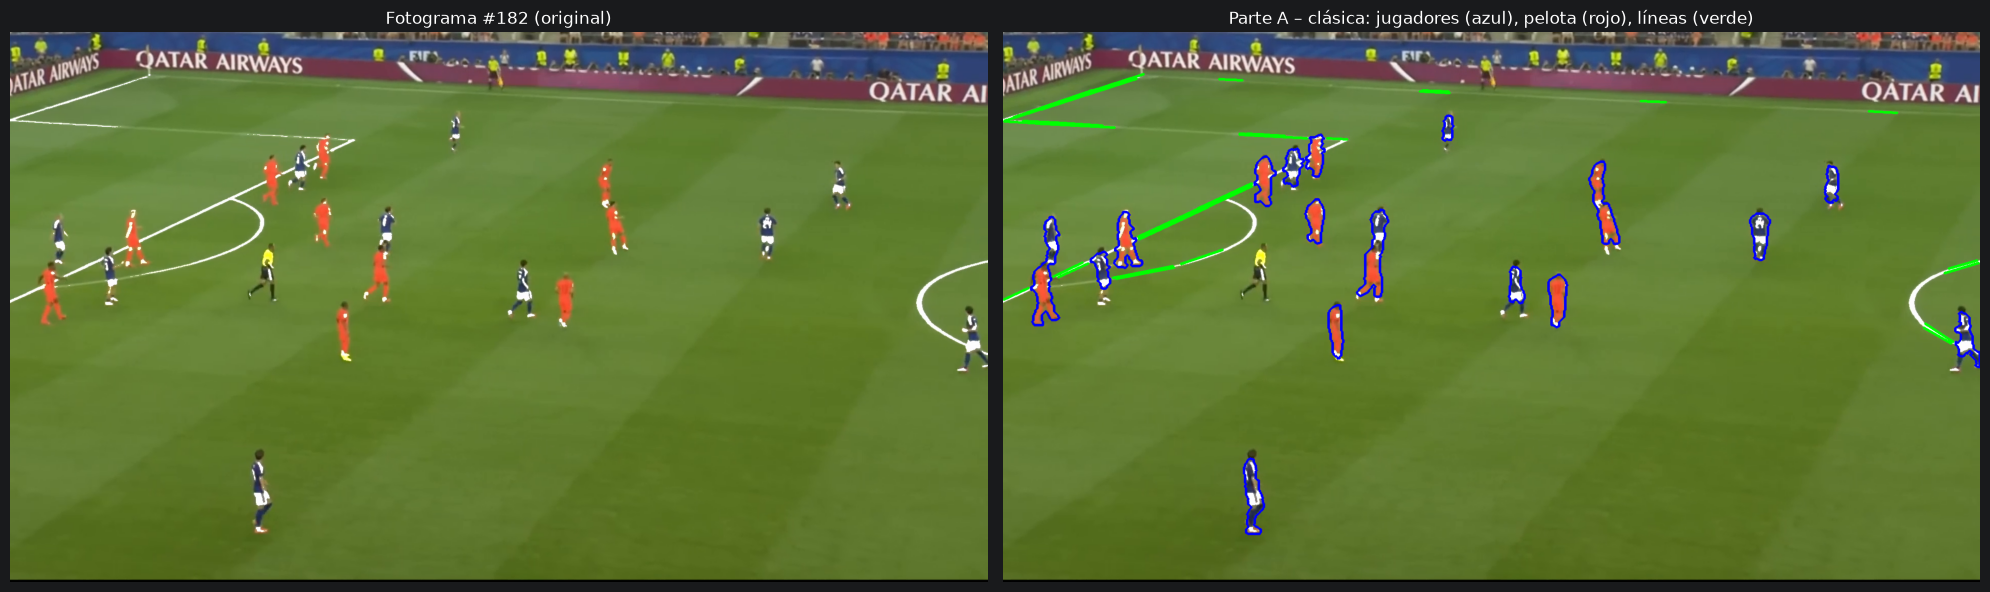

In [148]:
def anotar(frame, segmentos, jugadores, pelota):
    salida = frame.copy()
    grosor = max(2, frame.shape[1] // 640)  # grosor proporcional a la resolución

    for x1, y1, x2, y2 in segmentos:                          # líneas → verde
        cv2.line(salida, (int(x1), int(y1)), (int(x2), int(y2)), VERDE, grosor)

    if jugadores:                                             # jugadores → azul
        cv2.drawContours(salida, jugadores, -1, AZUL, grosor)

    if pelota is not None:                                    # pelota → rojo
        (cx, cy), radio = cv2.minEnclosingCircle(pelota)
        cv2.circle(salida, (int(cx), int(cy)), int(radio) + 3, ROJO, grosor)

    return salida


def resumen_texto(jugadores, pelota, segmentos):
    return f"jugadores: {len(jugadores)} | pelota: {'sí' if pelota is not None else 'no'} | líneas: {len(segmentos)}"


anotada_a = anotar(frame, segmentos_a, jugadores_a, pelota_a)
print("Versión clásica →", resumen_texto(jugadores_a, pelota_a, segmentos_a))

fig, ejes = plt.subplots(1, 2, figsize=(20, 7))
ejes[0].imshow(bgr2rgb(frame)); ejes[0].set_title(f"Fotograma #{indice} (original)")
ejes[1].imshow(bgr2rgb(anotada_a)); ejes[1].set_title("Parte A – clásica: jugadores (azul), pelota (rojo), líneas (verde)")
for eje in ejes:
    eje.axis("off")
plt.tight_layout()
plt.show()

---
# PARTE B – Versión con YOLO

La versión clásica tiene dificultades cuando dos jugadores se superponen (aparecen como una sola mancha), cuando un jugador está sobre una línea o cuando la pelota toca a un jugador. En esta parte reemplazamos la **localización** de jugadores y pelota por un detector de objetos basado en redes neuronales, pero mantenemos las técnicas clásicas para obtener los **contornos** y las **líneas**.

## B1. Instalación y carga del detector YOLO

YOLO (*You Only Look Once*) es una red neuronal convolucional que, en una sola pasada, devuelve **cajas delimitadoras** (*bounding boxes*) con una clase y un nivel de confianza. Usamos un modelo preentrenado en el dataset COCO, donde la clase `0` es *person* y la `32` es *sports ball*.

- La librería `ultralytics` se instala solo si falta (con `pip` en Colab, o con `uv pip` en un entorno local creado con `uv`, que no incluye `pip`).
- El modelo corre en la **GPU** si hay una compatible (en Colab: *Entorno de ejecución → Cambiar tipo de entorno → GPU T4*); si no, en la **CPU**, que es más lento pero funciona igual.

In [149]:
import importlib.util
import shutil
import subprocess
import sys
import warnings

# Instalamos ultralytics (YOLO) únicamente si no está disponible en el entorno.
# En Colab se usa pip; en un entorno local creado con uv (que no trae pip) se usa "uv pip".
if importlib.util.find_spec("ultralytics") is None:
    if importlib.util.find_spec("pip") is not None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
    elif shutil.which("uv"):
        subprocess.check_call(["uv", "pip", "install", "-q", "--python", sys.executable, "ultralytics"])
    else:
        raise ImportError("Falta ultralytics: instalalo con 'pip install ultralytics' o 'uv add ultralytics'")

import torch
from ultralytics import YOLO  # detector de objetos preentrenado

CLASE_PERSONA = 0   # clases del dataset COCO que nos interesan
CLASE_PELOTA = 32


def elegir_dispositivo():
    # Usa la GPU solo si PyTorch fue compilado para su arquitectura (sm_XY);
    # GPUs viejas (p. ej. una MX230, sm_61) no son compatibles y se usa la CPU.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # oculta los avisos de PyTorch sobre GPUs no soportadas
        if torch.cuda.is_available():
            mayor, menor = torch.cuda.get_device_capability(0)
            if f"sm_{mayor}{menor}" in torch.cuda.get_arch_list():
                return 0
    return "cpu"


DISPOSITIVO = elegir_dispositivo()
print("Dispositivo para YOLO:", "GPU" if DISPOSITIVO == 0 else "CPU")

# Se descarga automáticamente la primera vez
modelo = YOLO(MODELO_YOLO)

Dispositivo para YOLO: CPU


## B2. Detección de personas y pelota

Corremos el modelo una sola vez sobre el fotograma pidiendo solo las clases *person* y *sports ball*, y separamos las detecciones según su clase y su confianza mínima.

Usamos `imgsz=1280` (mayor que el valor por defecto, 640) porque la pelota ocupa muy pocos píxeles en una toma abierta y a baja resolución desaparece.

YOLO **solo nos da cajas rectangulares**; el **contorno** real de cada jugador lo obtenemos después con técnicas clásicas.

In [150]:
def detectar_objetos(frame):
    # Devuelve dos listas de (x1, y1, x2, y2, confianza): personas y pelotas
    resultado = modelo.predict(
        frame,
        classes=[CLASE_PERSONA, CLASE_PELOTA],
        conf=min(CONF_JUGADOR, CONF_PELOTA),
        imgsz=IMGSZ_YOLO,
        device=DISPOSITIVO,
        verbose=False,
    )[0]
    personas, pelotas = [], []
    for caja, clase, conf in zip(
        resultado.boxes.xyxy.cpu().numpy(),
        resultado.boxes.cls.cpu().numpy().astype(int),
        resultado.boxes.conf.cpu().numpy(),
    ):
        x1, y1, x2, y2 = caja.astype(int)
        if clase == CLASE_PERSONA and conf >= CONF_JUGADOR:
            personas.append((x1, y1, x2, y2, float(conf)))
        elif clase == CLASE_PELOTA and conf >= CONF_PELOTA:
            pelotas.append((x1, y1, x2, y2, float(conf)))
    return personas, pelotas


personas, pelotas_yolo = detectar_objetos(frame)
print(f"YOLO → personas: {len(personas)} | pelotas: {len(pelotas_yolo)}")

YOLO → personas: 28 | pelotas: 0


## B3. Jugadores: segmentación dentro de cada caja → contorno azul

Para cada persona detectada:

1. **Filtro por cancha**: tomamos el punto de apoyo (centro del borde inferior de la caja, los pies). Si cae fuera de la región de la cancha (dilatada un poco para tolerar a quienes pisan la línea lateral), la descartamos: es público, un suplente o alguien del cuerpo técnico.
2. **Región de interés (ROI)**: recortamos la máscara de pasto a la caja.
3. **Segmentación figura/fondo**: dentro de la caja, el fondo es pasto (verde) y el jugador es **no‑verde** → invertimos la máscara con `cv2.bitwise_not`.
4. **Morfología**: una apertura quita líneas finas de cal que cruzan la caja y un cierre rellena huecos del cuerpo.
5. **Contorno**: `cv2.findContours` y nos quedamos con el de mayor área (el jugador). Lo trasladamos a coordenadas de la imagen completa sumando `(x1, y1)`.
6. Si la segmentación falla (por ejemplo, el jugador está sobre una zona sin pasto), usamos como contorno el rectángulo de la caja.

A diferencia de la versión clásica, dos jugadores superpuestos tienen cada uno su propia caja y, por lo tanto, su propio contorno.

In [151]:
def contornos_jugadores_yolo(frame, pasto, cancha, personas):
    alto, ancho = frame.shape[:2]
    mascara_jugadores = np.zeros((alto, ancho), dtype=np.uint8)
    contornos, cajas = [], []

    # Cancha un poco "agrandada" para aceptar jugadores pisando la línea lateral
    cancha_tolerante = cv2.dilate(cancha, KERNEL_5, iterations=6)

    for x1, y1, x2, y2, _ in personas:
        x1, y1 = max(x1, 0), max(y1, 0)
        x2, y2 = min(x2, ancho - 1), min(y2, alto - 1)
        if x2 - x1 < 3 or y2 - y1 < 3:
            continue

        # 1) ¿Los pies están dentro de la cancha?
        pie_x, pie_y = (x1 + x2) // 2, y2
        if cancha_tolerante[pie_y, pie_x] == 0:
            continue

        # 2-3) Dentro de la caja: jugador = todo lo que NO es pasto
        roi = cv2.bitwise_not(pasto[y1:y2, x1:x2])

        # 4) Apertura (quita líneas finas) y cierre (rellena el cuerpo)
        roi = cv2.morphologyEx(roi, cv2.MORPH_OPEN, KERNEL_3)
        roi = cv2.morphologyEx(roi, cv2.MORPH_CLOSE, KERNEL_5, iterations=2)

        # 5) Contorno más grande dentro de la caja
        cs, _ = cv2.findContours(roi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        area_caja = (x2 - x1) * (y2 - y1)
        if cs and cv2.contourArea(max(cs, key=cv2.contourArea)) > 0.15 * area_caja:
            c = max(cs, key=cv2.contourArea) + np.array([[x1, y1]])  # a coordenadas globales
        else:
            # 6) Respaldo: contorno rectangular de la caja
            c = np.array([[[x1, y1]], [[x2, y1]], [[x2, y2]], [[x1, y2]]])

        contornos.append(c)
        cajas.append((x1, y1, x2 - x1, y2 - y1))
        cv2.drawContours(mascara_jugadores, [c], -1, 255, thickness=cv2.FILLED)

    return contornos, mascara_jugadores, cajas


if hay_cancha:
    jugadores_b, mascara_jug_b, cajas_b = contornos_jugadores_yolo(frame, pasto, cancha, personas)
else:
    jugadores_b, mascara_jug_b, cajas_b = [], None, []
print(f"Jugadores dentro de la cancha (YOLO): {len(jugadores_b)}")

Jugadores dentro de la cancha (YOLO): 22


## B4. Pelota: YOLO, con el método clásico como respaldo → contorno rojo

1. Si YOLO encontró una *sports ball* dentro de la cancha, nos quedamos con la de mayor confianza. Dentro de su caja (un poco agrandada) umbralizamos los píxeles claros y extraemos su contorno; si no se puede, usamos el círculo inscripto en la caja.
2. Si YOLO no la encuentra (algo habitual, porque la pelota mide pocos píxeles) y `USAR_RESPALDO_PELOTA` está activado, aplicamos la función `pelota_clasica` de la Parte A, excluyendo las cajas de los jugadores de YOLO.

Si ninguna de las dos opciones la encuentra, **no se dibuja nada en rojo**.

In [152]:
def pelota_yolo(frame, pasto, cancha, pelotas_yolo, excluir, ref):
    alto, ancho = frame.shape[:2]

    # --- Opción 1: YOLO ----------------------------------------------------
    def en_cancha(p):
        cx, cy = min((p[0] + p[2]) // 2, ancho - 1), min((p[1] + p[3]) // 2, alto - 1)
        return cancha[cy, cx] > 0

    candidatas = [p for p in pelotas_yolo if en_cancha(p)]
    if candidatas:
        x1, y1, x2, y2, conf = max(candidatas, key=lambda p: p[4])
        m = max(2, (x2 - x1) // 4)  # margen para no cortar el borde de la pelota
        x1, y1 = max(x1 - m, 0), max(y1 - m, 0)
        x2, y2 = min(x2 + m, ancho), min(y2 + m, alto)
        hsv = cv2.cvtColor(frame[y1:y2, x1:x2], cv2.COLOR_BGR2HSV)
        clara = mascara_blanca(hsv, ref, DELTA_V_PELOTA)
        cs, _ = cv2.findContours(clara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        if cs:
            return max(cs, key=cv2.contourArea) + np.array([[x1, y1]]), f"YOLO (conf {conf:.2f})"
        # Si no se pudo segmentar, usamos el círculo inscripto en la caja
        centro = ((x1 + x2) // 2, (y1 + y2) // 2)
        radio = max(x2 - x1, y2 - y1) // 2
        circulo = cv2.ellipse2Poly(centro, (radio, radio), 0, 0, 360, 10).reshape(-1, 1, 2)
        return circulo, f"YOLO (conf {conf:.2f})"

    # --- Opción 2: respaldo clásico (Parte A) ------------------------------
    if USAR_RESPALDO_PELOTA:
        c, circ = pelota_clasica(frame, pasto, cancha, excluir, ref)
        if c is not None:
            return c, f"respaldo clásico (circularidad {circ:.2f})"
    return None, None


if hay_cancha:
    excluir_b = mascara_exclusion(*frame.shape[:2], cajas_b, mascara_jug_b)
    pelota_b, metodo_pelota = pelota_yolo(frame, pasto, cancha, pelotas_yolo, excluir_b, ref)
else:
    pelota_b, metodo_pelota = None, None
print("Pelota (YOLO):", f"sí, por {metodo_pelota}" if pelota_b is not None else "no encontrada")

Pelota (YOLO): no encontrada


## B5. Resultado de la versión con YOLO y comparación con la clásica

Las líneas se detectan con la misma función de la Parte A (`detectar_lineas`), pero usando la máscara de jugadores de YOLO para excluir las camisetas. Mostramos ambos resultados lado a lado sobre el **mismo fotograma**.

A – clásica → jugadores: 17 | pelota: no | líneas: 35
B – YOLO    → jugadores: 22 | pelota: no | líneas: 36


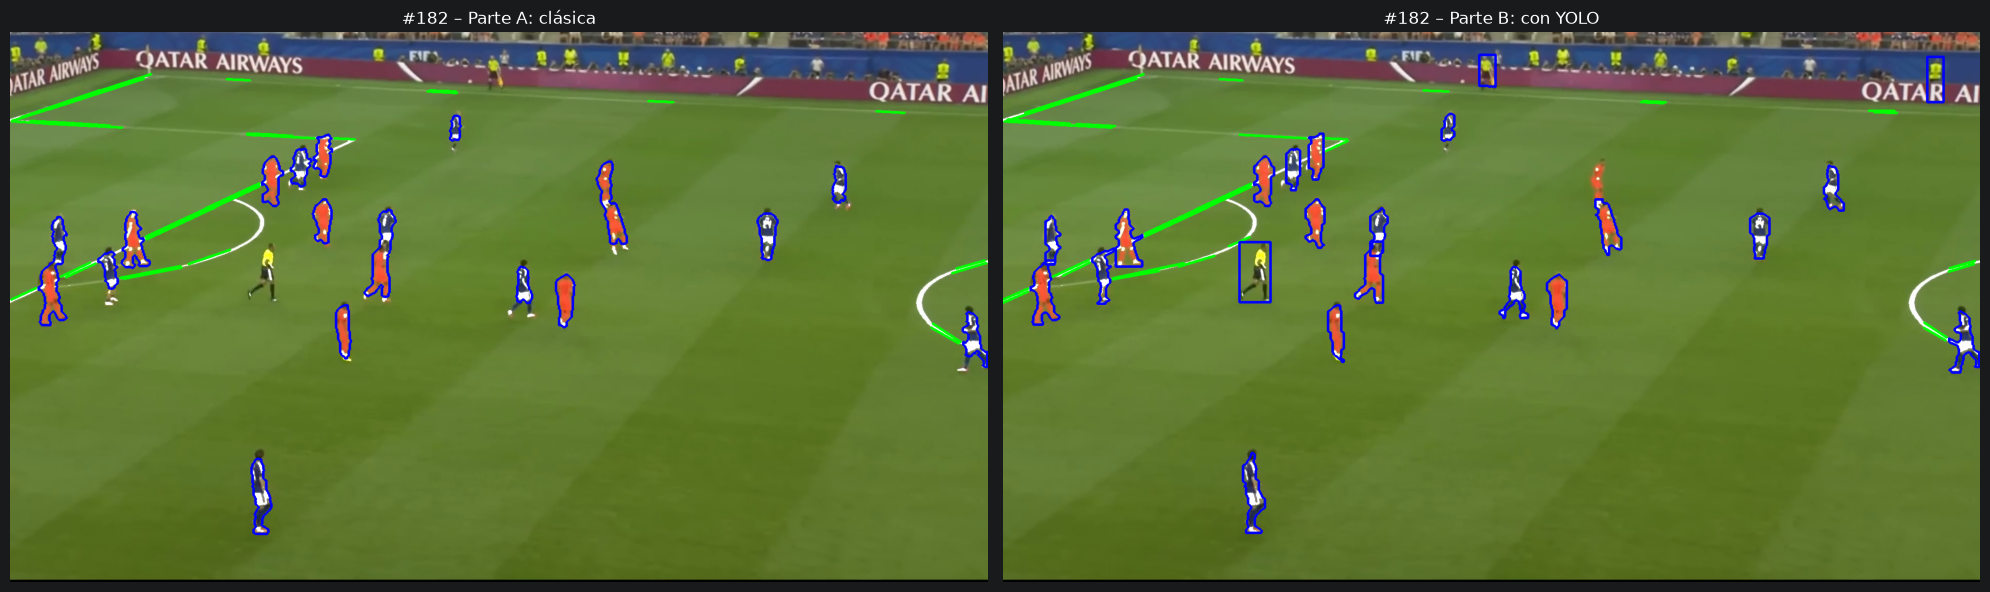

In [153]:
segmentos_b = detectar_lineas(frame, cancha, mascara_jug_b, ref)[0] if hay_cancha else []
anotada_b = anotar(frame, segmentos_b, jugadores_b, pelota_b)

print("A – clásica →", resumen_texto(jugadores_a, pelota_a, segmentos_a))
print("B – YOLO    →", resumen_texto(jugadores_b, pelota_b, segmentos_b))

fig, ejes = plt.subplots(1, 2, figsize=(20, 7))
ejes[0].imshow(bgr2rgb(anotada_a)); ejes[0].set_title(f"#{indice} – Parte A: clásica")
ejes[1].imshow(bgr2rgb(anotada_b)); ejes[1].set_title(f"#{indice} – Parte B: con YOLO")
for eje in ejes:
    eje.axis("off")
plt.tight_layout()
plt.show()

---
## 6. Pipeline completo y prueba con varios fotogramas al azar

Encapsulamos cada versión en una función (`analizar_clasico` y `analizar_yolo`) y las aplicamos a varios fotogramas aleatorios. Cada fila muestra el mismo fotograma con la versión clásica (izquierda) y con YOLO (derecha). Así se ve cómo se comporta cada una en distintas situaciones: tomas abiertas, jugadores superpuestos, tribuna, etc. Si en un fotograma no hay cancha visible, la imagen se muestra **sin ninguna marca**.

Volver a ejecutar esta celda elige nuevos fotogramas.

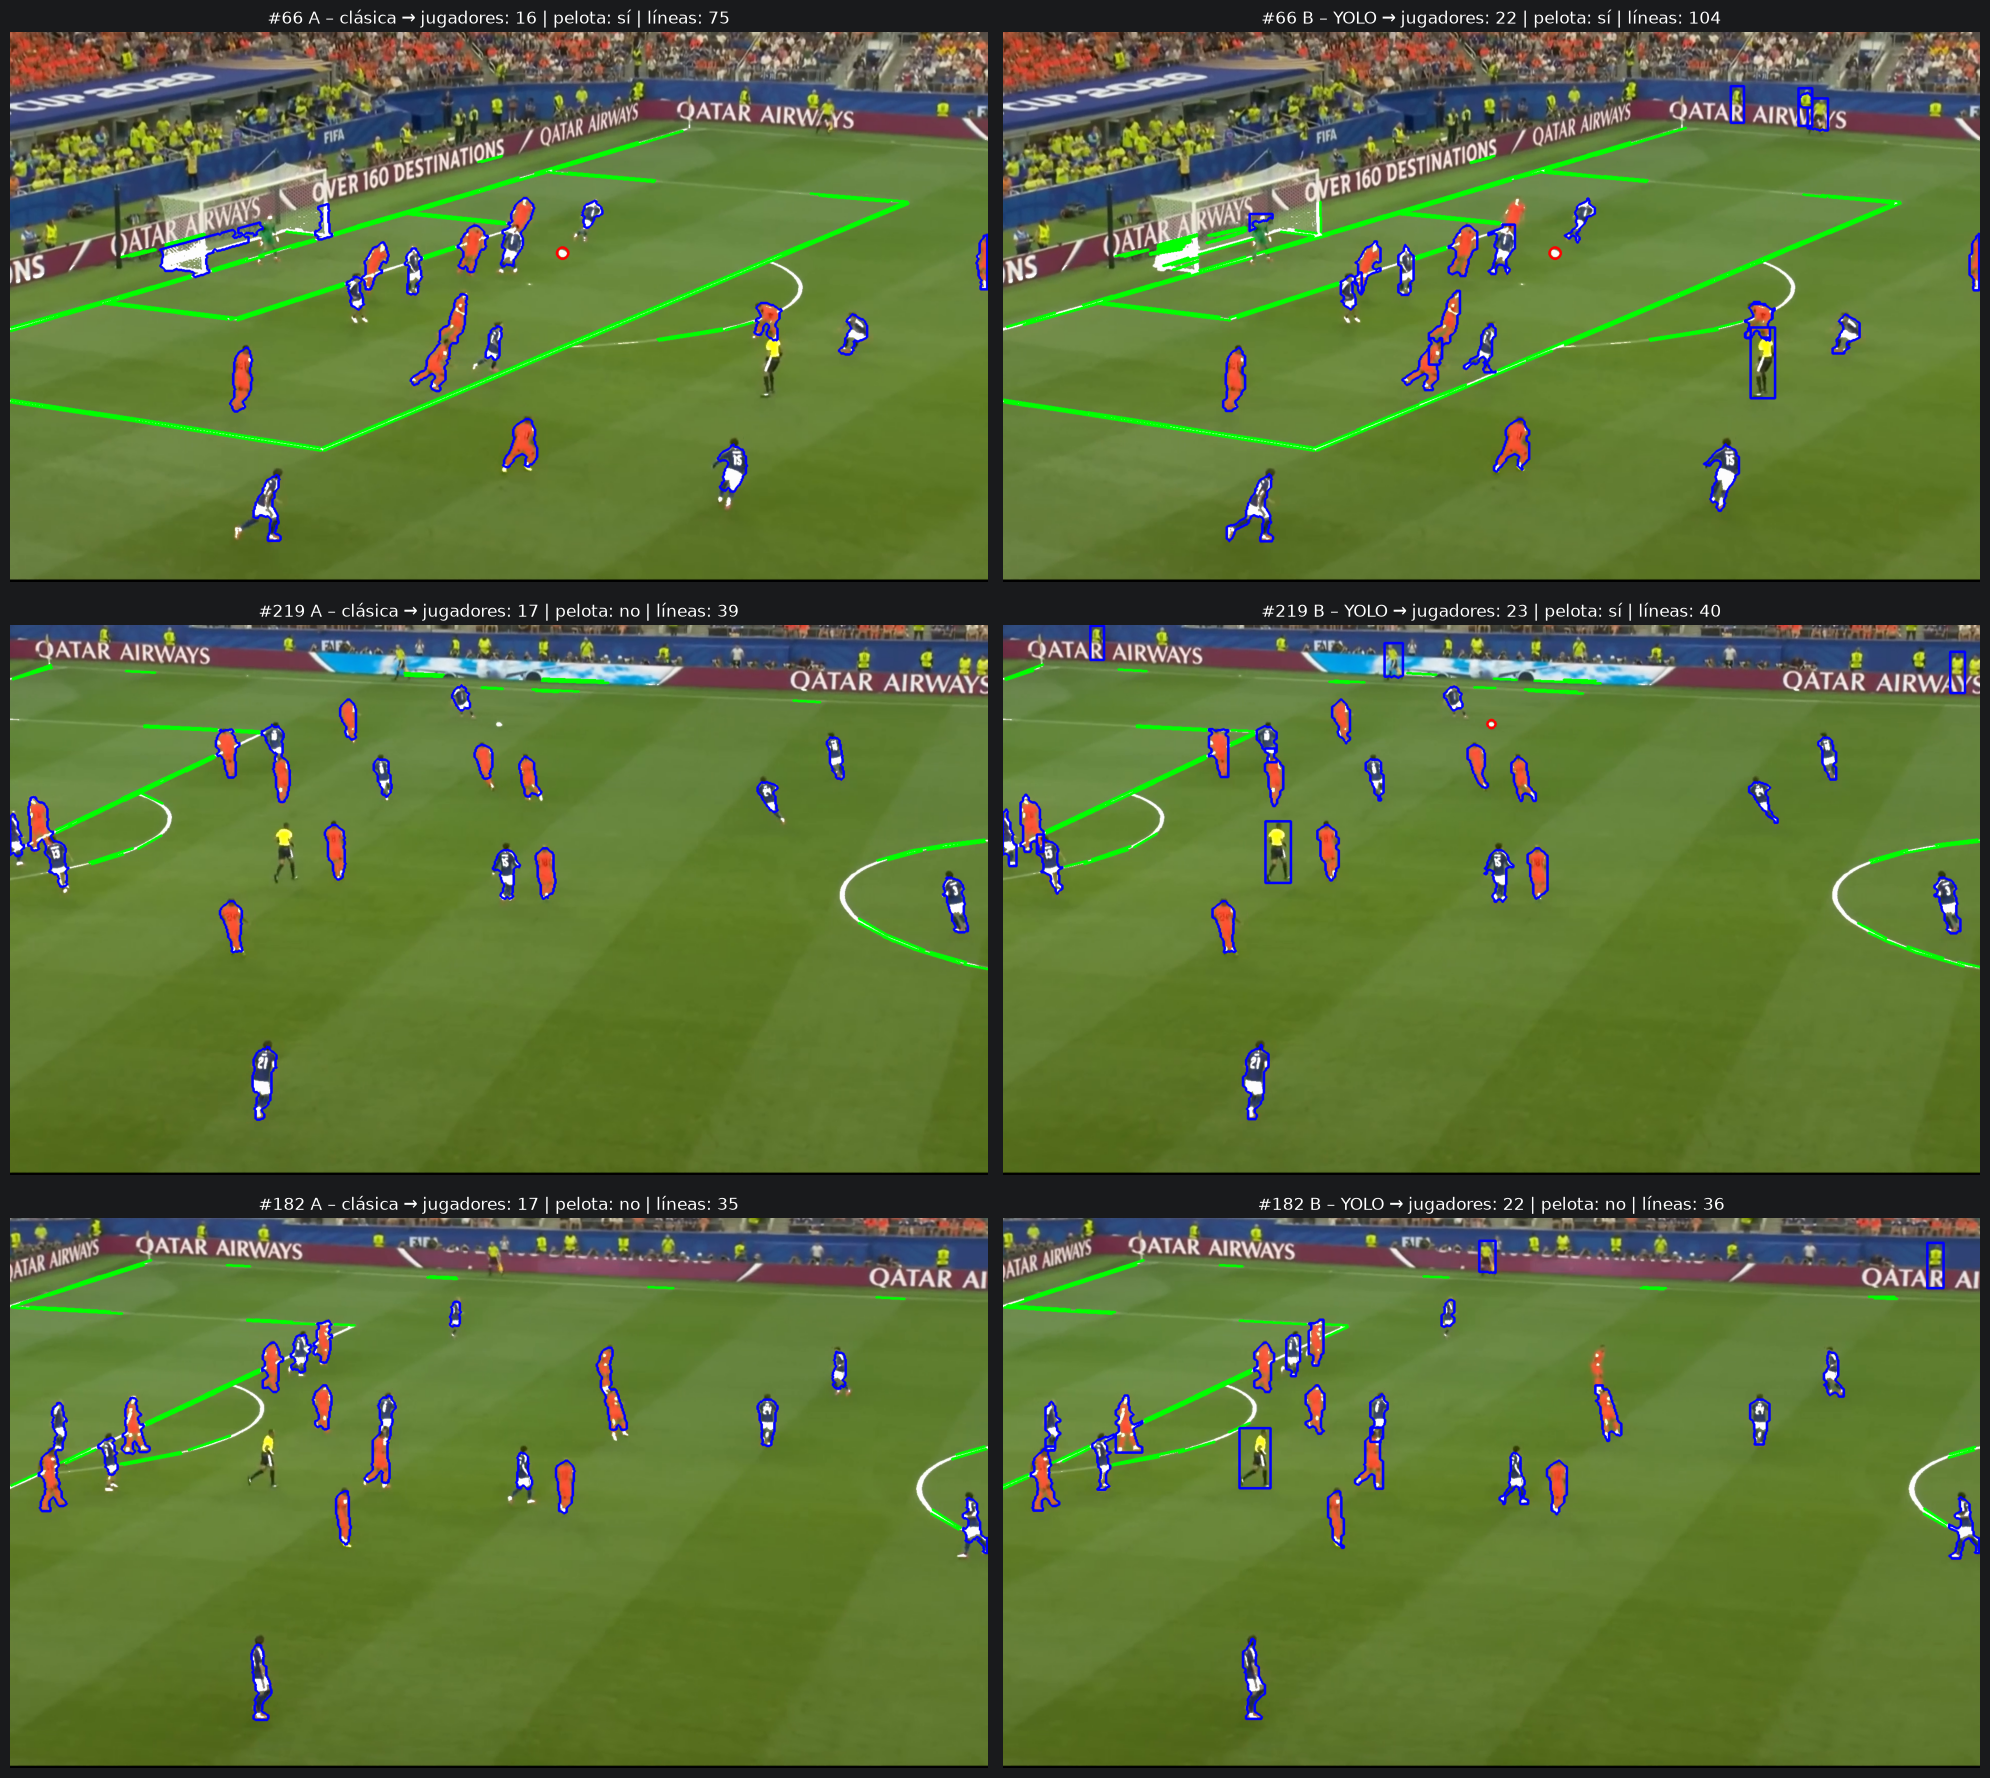

In [154]:
SIN_MARCAS = ([], None, [])  # (jugadores, pelota, segmentos) cuando no hay cancha


def analizar_clasico(frame):
    # Parte A: solo técnicas clásicas
    pasto, cancha, hay_cancha, _, ref = segmentar_cancha(frame)
    if not hay_cancha:
        return SIN_MARCAS
    jugadores, mascara, cajas, _, _ = jugadores_clasico(frame, pasto, cancha)
    segmentos, _, _ = detectar_lineas(frame, cancha, mascara, ref)
    pelota, _ = pelota_clasica(frame, pasto, cancha, mascara_exclusion(*frame.shape[:2], cajas, mascara), ref)
    return jugadores, pelota, segmentos


def analizar_yolo(frame):
    # Parte B: YOLO para localizar + técnicas clásicas para contornos y líneas
    pasto, cancha, hay_cancha, _, ref = segmentar_cancha(frame)
    if not hay_cancha:
        return SIN_MARCAS
    personas, pelotas = detectar_objetos(frame)
    jugadores, mascara, cajas = contornos_jugadores_yolo(frame, pasto, cancha, personas)
    segmentos, _, _ = detectar_lineas(frame, cancha, mascara, ref)
    pelota, _ = pelota_yolo(frame, pasto, cancha, pelotas, mascara_exclusion(*frame.shape[:2], cajas, mascara), ref)
    return jugadores, pelota, segmentos


N_PRUEBAS = 3  # @param {type:"integer"}
fig, ejes = plt.subplots(N_PRUEBAS, 2, figsize=(20, 6 * N_PRUEBAS), squeeze=False)

for i in range(N_PRUEBAS):
    f, idx = tomar_frame_aleatorio(VIDEO_PATH, rng)
    for j, (nombre, analizar) in enumerate([("A – clásica", analizar_clasico), ("B – YOLO", analizar_yolo)]):
        jugadores, pelota, segmentos = analizar(f)
        ejes[i, j].imshow(bgr2rgb(anotar(f, segmentos, jugadores, pelota)))
        ejes[i, j].set_title(f"#{idx} {nombre} → {resumen_texto(jugadores, pelota, segmentos)}")
        ejes[i, j].axis("off")

plt.tight_layout()
plt.show()

## 7. Conclusiones

- La **segmentación por color en HSV** del pasto es la base de las dos versiones: define la región de interés, permite descartar público y carteles, y funciona como interruptor cuando no hay cancha en la imagen.
- **Umbrales relativos (calibración automática):** con umbrales de color fijos, el sistema dejaba de funcionar al cambiar el contraste del video (las líneas y la pelota dejaban de ser "blancas" y los jugadores se "encogían" porque sus bordes difusos parecían pasto). Medir en cada fotograma la saturación y el brillo típicos del pasto y expresar los umbrales en relación con ellos hizo que el mismo código funcione con videos de distinto contraste. Por el mismo motivo, Canny se aplica sobre la máscara de líneas y no sobre la imagen: en un video suave el borde de una línea tenue tiene un gradiente muy bajo.
- **Versión clásica (A):** con filtrado por color, morfología (apertura del grosor de una línea, cierre, reconstrucción) y descriptores de forma y de contexto (área, relación de aspecto, solidez, circularidad, anillo de pasto) se detectan jugadores, pelota y líneas sin ningún modelo entrenado. Es rápida y fácil de explicar, pero depende de umbrales ajustados a mano: dos jugadores superpuestos se ven como una sola mancha, un jugador vestido de verde se confunde con el pasto, y la pelota pegada a un jugador o a una línea se pierde.
- **Versión con YOLO (B):** el detector separa a cada persona aunque estén superpuestas y es más robusto a cambios de iluminación y de cámara; los contornos y las líneas se siguen obteniendo con técnicas clásicas. A cambio necesita PyTorch, es más lenta sin GPU y tampoco ve siempre la pelota (por eso conserva el método clásico como respaldo).
- Las **líneas** se obtienen en ambas versiones con técnicas clásicas: filtrado de color, top‑hat, **detección de bordes de Canny** y **transformada de Hough**.

**Limitaciones comunes:** los umbrales de tamaño (grosor de línea, áreas) dependen del zoom de la cámara (se ajustan en la sección 2); un jugador tirado sobre una línea puede quedar unido a ella en la versión clásica; las líneas curvas (círculo central, medialuna) se aproximan con segmentos rectos cortos; y una pelota parcialmente tapada o muy borrosa por el movimiento puede no detectarse.